# Did the Ad Campaign Work? An A/B Test Analysis

**Business question:** Does showing users an advertisement increase purchases compared with showing a neutral public service announcement (PSA), and is the lift large enough to justify the cost?

**Data:** Public Kaggle dataset "Marketing A/B Testing" (588,101 users). Each user was shown either the ad (treatment) or a PSA (control). I analyze the completed experiment; I did not run it.

**Key findings**
- The ad group converted at **2.55%** vs. **1.79%** for the PSA group: a lift of **0.77 percentage points** (95% CI: 0.60 to 0.94; p < 0.001), or about **7.7 extra sales per 1,000 users**.
- The campaign pays for itself only if profit per sale exceeds a break-even threshold that depends on ad cost (table below).
- Conversion rises with exposure in *both* groups, so ad frequency should not be read as causal.
- **Recommendation:** continue the campaign if economics clear break-even, and run a follow-up test with a balanced split and randomized frequency.

In [1]:
import pandas as pd
df = pd.read_csv("marketing_AB.csv")
df.head()

,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


## 1. Data Quality Checks
Before testing anything, I confirm the data is trustworthy. The unnamed first column is just a row index, so I drop it.

In [2]:
df = df.drop(columns="Unnamed: 0")
print(df.shape)
print(df.isna().sum())
print("duplicate rows:", df.duplicated().sum())
print("duplicate user ids:", df["user id"].duplicated().sum())
print(df.dtypes)

(588101, 6)
user id          0
test group       0
converted        0
total ads        0
most ads day     0
most ads hour    0
dtype: int64
duplicate rows: 0
duplicate user ids: 0
user id          int64
test group         str
converted         bool
total ads        int64
most ads day       str
most ads hour    int64
dtype: object


**Result:** 588,101 users and six columns, with no missing values, no duplicate rows, and no duplicate user IDs. Each row is a distinct user, which the A/B test assumes.

## 2. Experiment Design
   - **Hypothesis:** Users shown the ad convert at a different rate than users shown the PSA.
   - **Primary metric:** conversion rate (share of users who purchased).
   - **Control:** a PSA, not "no ad." This measures the ad against a neutral message.

In [3]:
summary = df.groupby("test group")["converted"].agg(users="count", conversions="sum", rate="mean")
summary["share_of_users"] = summary["users"] / summary["users"].sum()
summary

,users,conversions,rate,share_of_users
test group,,,,
ad,564577,14423,0.025547,0.96
psa,23524,420,0.017854,0.04


**Result:** 564,577 users saw the ad (2.55% converted) and 23,524 saw the PSA (1.79% converted). The split is 96/4, which is unusual for an A/B test. The PSA arm has only 420 conversions, so it is the main source of uncertainty in everything that follows.

## 3. Is the Difference Real?
I test the difference in conversion rates with a two-proportion z-test and report a 95% confidence interval for the difference.

In [4]:
import numpy as np
from statsmodels.stats.proportion import proportions_ztest

ad = df[df["test group"] == "ad"]["converted"]
psa = df[df["test group"] == "psa"]["converted"]

n_ad, n_psa = len(ad), len(psa)
x_ad, x_psa = ad.sum(), psa.sum()
p_ad, p_psa = x_ad / n_ad, x_psa / n_psa

z, p_value = proportions_ztest([x_ad, x_psa], [n_ad, n_psa])

diff = p_ad - p_psa
se = np.sqrt(p_ad * (1 - p_ad) / n_ad + p_psa * (1 - p_psa) / n_psa)
ci_low, ci_high = diff - 1.96 * se, diff + 1.96 * se

print(f"ad rate: {p_ad:.4%} | psa rate: {p_psa:.4%}")
print(f"absolute lift: {diff*100:.4f} percentage points")
print(f"relative lift: {diff / p_psa:.1%}")
print(f"95% CI for difference: [{ci_low:.4%}, {ci_high:.4%}]")
print(f"z = {z:.2f}, p-value = {p_value:.2e}")

ad rate: 2.5547% | psa rate: 1.7854%
absolute lift: 0.7692 percentage points
relative lift: 43.1%
95% CI for difference: [0.5951%, 0.9434%]
z = 7.37, p-value = 1.71e-13


**Result:** The ad group converts 0.77 percentage points more often than the PSA group (a 43% relative lift). The 95% confidence interval is 0.60 to 0.94 points. The whole interval is above zero, and p < 0.001, so chance is a very unlikely explanation. The interval is wider than it would be with an even split, because the small PSA arm drives the uncertainty.

## 4. What Is the Lift Worth?
The dataset has no cost or revenue data. I convert the lift into **incremental sales per 1,000 users**, then compute the **break-even profit per sale** for several hypothetical ad costs. The "conservative" column uses the low end of the confidence interval.

*The cost figures below are assumptions, not data.*

In [5]:
print(f"Incremental sales per 1,000 users: {diff*1000:.1f} "
      f"(95% CI {ci_low*1000:.1f} to {ci_high*1000:.1f})")

costs_per_1000 = [2, 5, 10, 20, 50]
rows = []
for c in costs_per_1000:
    rows.append({
        "ad cost per 1,000 users ($)": c,
        "break-even $ per sale (best estimate)": c / (diff * 1000),
        "break-even $ per sale (conservative)": c / (ci_low * 1000),
    })
pd.DataFrame(rows).round(2)

Incremental sales per 1,000 users: 7.7 (95% CI 6.0 to 9.4)


,"ad cost per 1,000 users ($)",break-even $ per sale (best estimate),break-even $ per sale (conservative)
0,2,0.26,0.34
1,5,0.65,0.84
2,10,1.30,1.68
3,20,2.60,3.36
4,50,6.50,8.40


**Result:** The ad produces about 7.7 extra sales per 1,000 users (95% CI: 6.0 to 9.4). For example, if showing the ad to 1,000 users costs $10, each extra sale must earn at least $1.30 in profit to break even ($1.68 under the conservative estimate). Use profit per sale (revenue minus product cost), not revenue.

## 5. Does Exposure Explain the Result?
Conversion appears to rise with the number of ads or PSAs a user saw. I group users by exposure level and compare the two groups within each level.

In [6]:
print("max total ads:", df["total ads"].max())
bins = [0, 2, 5, 10, 25, 50, 100, 250, 2500]
df["ads_bucket"] = pd.cut(df["total ads"], bins=bins)
by_bucket = df.pivot_table(index="ads_bucket", columns="test group",
                           values="converted", aggfunc=["mean", "count"], observed=True)
by_bucket.round(4)

max total ads: 2065


mean           count      
test group       ad     psa      ad   psa
ads_bucket                               
(0, 2]       0.0019  0.0014   92209  4224
(2, 5]       0.0032  0.0044   77753  3637
(5, 10]      0.0049  0.0067   79537  3415
(10, 25]     0.0102  0.0100  163135  6112
(25, 50]     0.0354  0.0266   85740  3273
(50, 100]    0.1163  0.0577   44149  1853
(100, 250]   0.1735  0.1123   18584   864
(250, 2500]  0.1597  0.1575    3470   146

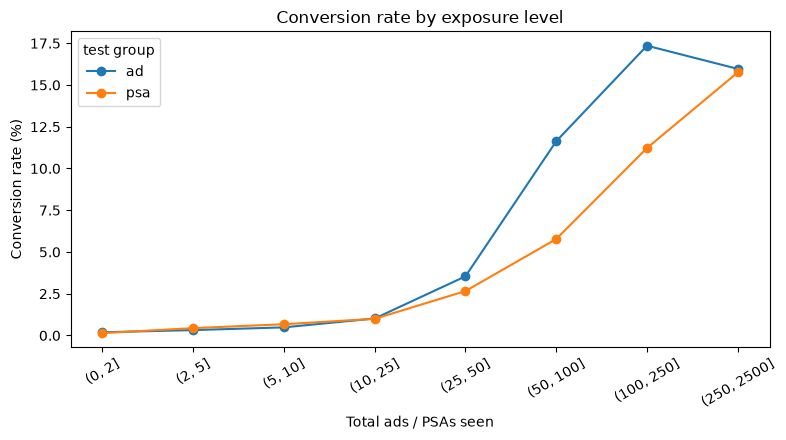

In [7]:
import matplotlib.pyplot as plt

rates = by_bucket["mean"] * 100
rates.index = rates.index.astype(str)
ax = rates.plot(marker="o", figsize=(8, 4.5))
ax.set_ylabel("Conversion rate (%)")
ax.set_xlabel("Total ads / PSAs seen")
ax.set_title("Conversion rate by exposure level")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Result:** Conversion climbs steeply with exposure in **both** groups, rising from under 0.2% for light users to roughly 16% for the heaviest users, including in the PSA group, which sees no product ad. So the number of messages a user sees mostly reflects how engaged that user is, and should not be read as "more ads cause more sales." Within exposure levels, the ad's advantage appears concentrated among users who saw roughly 25 to 250 messages (for example, 11.6% vs. 5.8% at 50 to 100 and 17.4% vs. 11.2% at 100 to 250). The lowest and highest buckets are close or noisy.

*Caution: this is exploratory. Total exposure is measured after assignment, I compared eight buckets without adjusting for multiple comparisons, and the exposure buckets are unequal in width. I treat this as a hypothesis to test, not a conclusion.*

## 6. Recommendation
The ad lifts conversion by 0.77 percentage points (95% CI: 0.60 to 0.94), or about 7.7 extra sales per 1,000 users. **Continue the campaign if profit per sale exceeds the break-even thresholds above for the actual cost per 1,000 users.**

**Next test:**
1. Use a balanced split (for example, 50/50) to tighten the estimate.
2. Track revenue and cost so profitability can be measured instead of assumed.
3. Randomize ad frequency to test directly whether the benefit is concentrated among heavily exposed users.
4. Add a no-ad control to separate the effect of advertising from the effect of any message.

## 7. Limitations
1. **Control group:** the control is a PSA, so the result is ad vs. a neutral message, not ad vs. nothing.
2. **Unbalanced allocation:** the 96/4 split widens uncertainty, since the PSA arm has only 420 conversions.
3. **No timestamps:** I can't check novelty effects, seasonality, or trends over time.
4. **No revenue or cost data:** break-even figures use hypothetical costs.
5. **Exploratory exposure analysis:** total ads is a post-assignment variable, and bucket comparisons were not adjusted for multiple testing.
6. **No pre-assignment variables:** I can't verify that randomization produced balanced groups.

## Methods and Reproducibility
Two-proportion z-test (statsmodels) with a Wald 95% confidence interval for the difference in proportions. Analysis in Python (pandas, numpy, statsmodels, matplotlib). Data: Kaggle "Marketing A/B Testing" dataset (faviovaz). To reproduce, download `marketing_AB.csv`, place it in the same folder as this notebook, and run all cells in order.